In [21]:
from pathlib import Path
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras.applications import EfficientNetB0
from sklearn.metrics.pairwise import cosine_similarity

In [ ]:
current_path = Path.cwd()
project_root = current_path.parent

raw_dataset_root = (
    project_root
    / "data"
    / "Raw"
    / "Stanford_Online_Products"
)

processed_data_dir = (
    project_root
    / "data"
    / "processed"
)

metadata_path = (
    processed_data_dir
    / "selected_product_metadata.csv"
)

print("Current path:", current_path)
print("Project root:", project_root)
print("Raw dataset root:", raw_dataset_root)
print("Metadata path:", metadata_path)
print("Metadata file exists:", metadata_path.exists())

Current path: c:\Users\hunte\VS Code\Visual Product Similarity\notebooks
Project root: c:\Users\hunte\VS Code\Visual Product Similarity
Raw dataset root: c:\Users\hunte\VS Code\Visual Product Similarity\data\Raw\Stanford_Online_Products
Metadata path: c:\Users\hunte\VS Code\Visual Product Similarity\data\processed\selected_product_metadata.csv
Metadata file exists: True


In [3]:
product_metadata = pd.read_csv(metadata_path)

print("Rows:", len(product_metadata))
print(
    "Product classes:",
    product_metadata["class_id"].nunique()
)
print(
    "Categories:",
    product_metadata["super_class_id"].nunique()
)

product_metadata.head()

Rows: 3095
Product classes: 600
Categories: 12


,image_id,class_id,super_class_id,path,category_name,full_path,image_exists,width,height,mode,format,is_corrupted
0,84,16,1,bicycle_final/111645993618_0.JPG,bicycle,c:\Users\hunte\VS Code\Visual Product Similari...,True,400,400,RGB,JPEG,False
1,85,16,1,bicycle_final/111645993618_1.JPG,bicycle,c:\Users\hunte\VS Code\Visual Product Similari...,True,400,400,RGB,JPEG,False
2,86,16,1,bicycle_final/111645993618_2.JPG,bicycle,c:\Users\hunte\VS Code\Visual Product Similari...,True,400,400,RGB,JPEG,False
3,87,16,1,bicycle_final/111645993618_3.JPG,bicycle,c:\Users\hunte\VS Code\Visual Product Similari...,True,400,400,RGB,JPEG,False
4,129,25,1,bicycle_final/111688507119_0.JPG,bicycle,c:\Users\hunte\VS Code\Visual Product Similari...,True,400,400,RGB,JPEG,False


In [4]:
product_metadata["full_path"] = product_metadata["path"].apply(
    lambda relative_path: raw_dataset_root / relative_path
)

print(
    "Existing selected images:",
    product_metadata["full_path"].apply(
        lambda image_path: image_path.exists()
    ).sum()
)

print(
    "Missing selected images:",
    (~product_metadata["full_path"].apply(
        lambda image_path: image_path.exists()
    )).sum()
)

product_metadata[
    [
        "image_id",
        "class_id",
        "category_name",
        "path",
        "full_path"
    ]
].head()

Existing selected images: 3095
Missing selected images: 0


,image_id,class_id,category_name,path,full_path
0,84,16,bicycle,bicycle_final/111645993618_0.JPG,c:\Users\hunte\VS Code\Visual Product Similari...
1,85,16,bicycle,bicycle_final/111645993618_1.JPG,c:\Users\hunte\VS Code\Visual Product Similari...
2,86,16,bicycle,bicycle_final/111645993618_2.JPG,c:\Users\hunte\VS Code\Visual Product Similari...
3,87,16,bicycle,bicycle_final/111645993618_3.JPG,c:\Users\hunte\VS Code\Visual Product Similari...
4,129,25,bicycle,bicycle_final/111688507119_0.JPG,c:\Users\hunte\VS Code\Visual Product Similari...


Image ID: 84
Class ID: 16
Category: bicycle
Image path: c:\Users\hunte\VS Code\Visual Product Similarity\data\Raw\Stanford_Online_Products\bicycle_final\111645993618_0.JPG
Image size: (400, 400)
Image mode: RGB
Image format: JPEG


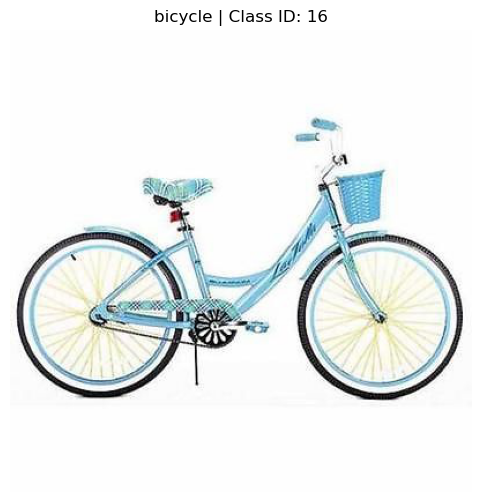

In [5]:
sample_row = product_metadata.iloc[0]

sample_image_path = sample_row["full_path"]

with Image.open(sample_image_path) as sample_image:
    print("Image ID:", sample_row["image_id"])
    print("Class ID:", sample_row["class_id"])
    print("Category:", sample_row["category_name"])
    print("Image path:", sample_image_path)
    print("Image size:", sample_image.size)
    print("Image mode:", sample_image.mode)
    print("Image format:", sample_image.format)

    plt.figure(figsize=(6, 6))
    plt.imshow(sample_image)
    plt.title(
        f"{sample_row['category_name']} "
        f"| Class ID: {sample_row['class_id']}"
    )
    plt.axis("off")
    plt.show()

In [6]:
with Image.open(sample_image_path) as image:
    image_rgb = image.convert('RGB')
    image_resized = image_rgb.resize((224, 224))
    image_array = np.array(image_resized)
    image_batch = np.expand_dims(image_array, axis = 0)

print("Original image size:", image.size)
print("RGB image mode:", image_rgb.mode)
print("Resized image size:", image_resized.size)
print("Array shape:", image_array.shape)
print("Batch shape:", image_batch.shape)
print("Array data type:", image_array.dtype)

Original image size: (400, 400)
RGB image mode: RGB
Resized image size: (224, 224)
Array shape: (224, 224, 3)
Batch shape: (1, 224, 224, 3)
Array data type: uint8


In [8]:
preprocessed_image = preprocess_input(
    image_batch.astype("float32")
)

print("Shape after preprocessing:", preprocessed_image.shape)
print("Data type after preprocessing:", preprocessed_image.dtype)
print("Minimum pixel value:", preprocessed_image.min())
print("Maximum pixel value:", preprocessed_image.max())

Shape after preprocessing: (1, 224, 224, 3)
Data type after preprocessing: float32
Minimum pixel value: 0.0
Maximum pixel value: 255.0


In [10]:
feature_extractor = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    pooling="avg",
    input_shape=(224, 224, 3)
)

print("Feature extractor loaded successfully")
print("Model input shape:", feature_extractor.input_shape)
print("Model output shape:", feature_extractor.output_shape)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 9s 1us/step
Feature extractor loaded successfully
Model input shape: (None, 224, 224, 3)
Model output shape: (None, 1280)


In [13]:
sample_embedding = feature_extractor.predict(
    preprocessed_image,
    verbose=0
)

print("Embedding shape:", sample_embedding.shape)
print("Embedding data type:", sample_embedding.dtype)
print("First 10 embedding values:")
print(sample_embedding[0][:10])

Embedding shape: (1, 1280)
Embedding data type: float32
First 10 embedding values:
[-0.14955539  0.02244418 -0.19659589  0.03457382 -0.08168236  0.19419612
 -0.11732989 -0.12344775 -0.12505086  0.1893146 ]


In [16]:
same_product_row = product_metadata[
    (product_metadata["class_id"] == sample_row["class_id"])
    & (product_metadata["image_id"] != sample_row["image_id"])
].iloc[0]

different_product_row = product_metadata[
    product_metadata["category_name"] != sample_row["category_name"]
].iloc[0]

print("Query image:")
print(
    "Image ID:", sample_row["image_id"],
    "| Class ID:", sample_row["class_id"],
    "| Category:", sample_row["category_name"]
)

print("\nSame-product image:")
print(
    "Image ID:", same_product_row["image_id"],
    "| Class ID:", same_product_row["class_id"],
    "| Category:", same_product_row["category_name"]
)

print("\nDifferent-product image:")
print(
    "Image ID:", different_product_row["image_id"],
    "| Class ID:", different_product_row["class_id"],
    "| Category:", different_product_row["category_name"]
)

Query image:
Image ID: 84 | Class ID: 16 | Category: bicycle

Same-product image:
Image ID: 85 | Class ID: 16 | Category: bicycle

Different-product image:
Image ID: 4203 | Class ID: 585 | Category: cabinet


In [17]:
def preprocess_image(image_path):
    with Image.open(image_path) as image:
        image = image.convert("RGB")
        image = image.resize((224, 224))
        image_array = np.array(image, dtype=np.float32)
        image_batch = np.expand_dims(image_array, axis=0)
        preprocessed_batch = preprocess_input(image_batch)

    return preprocessed_batch

In [18]:
same_product_image = preprocess_image(
    same_product_row["full_path"]
)

different_product_image = preprocess_image(
    different_product_row["full_path"]
)

print("Same-product input shape:", same_product_image.shape)
print("Different-product input shape:", different_product_image.shape)

Same-product input shape: (1, 224, 224, 3)
Different-product input shape: (1, 224, 224, 3)


In [19]:
same_product_embedding = feature_extractor.predict(
    same_product_image,
    verbose=0
)

different_product_embedding = feature_extractor.predict(
    different_product_image,
    verbose=0
)

print("Same-product embedding shape:", same_product_embedding.shape)
print("Different-product embedding shape:", different_product_embedding.shape)


Same-product embedding shape: (1, 1280)
Different-product embedding shape: (1, 1280)


In [22]:
same_product_similarity = cosine_similarity(
    sample_embedding,
    same_product_embedding
)[0][0]

different_product_similarity = cosine_similarity(
    sample_embedding,
    different_product_embedding
)[0][0]

print(
    "Query vs same-product similarity:",
    same_product_similarity
)

print(
    "Query vs different-product similarity:",
    different_product_similarity
)

Query vs same-product similarity: 0.99999976
Query vs different-product similarity: 0.040523503


In [25]:
def extract_embedding(image_path, model):
    preprocessed_image = preprocess_image(image_path)

    embedding = model.predict(
        preprocessed_image,
        verbose=0
    )

    return embedding[0]

In [27]:
test_batch_rows = product_metadata.iloc[:8]

test_batch_paths = test_batch_rows["full_path"].tolist()

print("Number of selected images:", len(test_batch_paths))

for image_path in test_batch_paths:
    print(image_path)

Number of selected images: 8
c:\Users\hunte\VS Code\Visual Product Similarity\data\Raw\Stanford_Online_Products\bicycle_final\111645993618_0.JPG
c:\Users\hunte\VS Code\Visual Product Similarity\data\Raw\Stanford_Online_Products\bicycle_final\111645993618_1.JPG
c:\Users\hunte\VS Code\Visual Product Similarity\data\Raw\Stanford_Online_Products\bicycle_final\111645993618_2.JPG
c:\Users\hunte\VS Code\Visual Product Similarity\data\Raw\Stanford_Online_Products\bicycle_final\111645993618_3.JPG
c:\Users\hunte\VS Code\Visual Product Similarity\data\Raw\Stanford_Online_Products\bicycle_final\111688507119_0.JPG
c:\Users\hunte\VS Code\Visual Product Similarity\data\Raw\Stanford_Online_Products\bicycle_final\111688507119_1.JPG
c:\Users\hunte\VS Code\Visual Product Similarity\data\Raw\Stanford_Online_Products\bicycle_final\111688507119_2.JPG
c:\Users\hunte\VS Code\Visual Product Similarity\data\Raw\Stanford_Online_Products\bicycle_final\111688507119_3.JPG


In [28]:
test_batch_images = []

for image_path in test_batch_paths:
    preprocessed_image = preprocess_image(image_path)

    test_batch_images.append(
        preprocessed_image[0]
    )

test_batch_array = np.stack(test_batch_images)

print("Number of images in batch:", len(test_batch_images))
print("Batch shape:", test_batch_array.shape)
print("Batch data type:", test_batch_array.dtype)

Number of images in batch: 8
Batch shape: (8, 224, 224, 3)
Batch data type: float32


In [29]:
test_batch_embeddings = feature_extractor.predict(
    test_batch_array,
    verbose=0
)

print("Batch embedding shape:", test_batch_embeddings.shape)
print("Batch embedding data type:", test_batch_embeddings.dtype)

print(
    "Contains NaN values:",
    np.isnan(test_batch_embeddings).any()
)

print(
    "Contains infinite values:",
    np.isinf(test_batch_embeddings).any()
)

Batch embedding shape: (8, 1280)
Batch embedding data type: float32
Contains NaN values: False
Contains infinite values: False


In [30]:
def extract_embeddings_in_batches(
    image_paths,
    model,
    batch_size=32
):
    all_embeddings = []

    total_images = len(image_paths)

    for start_index in range(
        0,
        total_images,
        batch_size
    ):
        end_index = min(
            start_index + batch_size,
            total_images
        )

        batch_paths = image_paths[
            start_index:end_index
        ]

        batch_images = []

        for image_path in batch_paths:
            preprocessed_image = preprocess_image(
                image_path
            )

            batch_images.append(
                preprocessed_image[0]
            )

        batch_array = np.stack(
            batch_images
        )

        batch_embeddings = model.predict(
            batch_array,
            verbose=0
        )

        all_embeddings.append(
            batch_embeddings
        )

        print(
            f"Processed {end_index}/{total_images} images"
        )

    final_embeddings = np.vstack(
        all_embeddings
    )

    return final_embeddings

In [31]:
function_test_embeddings = extract_embeddings_in_batches(
    test_batch_paths,
    feature_extractor,
    batch_size=4
)

print(
    "Final test shape:",
    function_test_embeddings.shape
)

Processed 4/8 images
Processed 8/8 images
Final test shape: (8, 1280)


In [32]:
all_image_paths = product_metadata["full_path"].tolist()

print("Total images:", len(all_image_paths))

Total images: 3095


In [33]:
all_embeddings = extract_embeddings_in_batches(
    all_image_paths,
    feature_extractor,
    batch_size=32
)

print("Final embedding matrix shape:", all_embeddings.shape)
print("Embedding data type:", all_embeddings.dtype)

Processed 32/3095 images
Processed 64/3095 images
Processed 96/3095 images
Processed 128/3095 images
Processed 160/3095 images
Processed 192/3095 images
Processed 224/3095 images
Processed 256/3095 images
Processed 288/3095 images
Processed 320/3095 images
Processed 352/3095 images
Processed 384/3095 images
Processed 416/3095 images
Processed 448/3095 images
Processed 480/3095 images
Processed 512/3095 images
Processed 544/3095 images
Processed 576/3095 images
Processed 608/3095 images
Processed 640/3095 images
Processed 672/3095 images
Processed 704/3095 images
Processed 736/3095 images
Processed 768/3095 images
Processed 800/3095 images
Processed 832/3095 images
Processed 864/3095 images
Processed 896/3095 images
Processed 928/3095 images
Processed 960/3095 images
Processed 992/3095 images
Processed 1024/3095 images
Processed 1056/3095 images
Processed 1088/3095 images
Processed 1120/3095 images
Processed 1152/3095 images
Processed 1184/3095 images
Processed 1216/3095 images
Processe

In [35]:
embeddings_path = (
    processed_data_dir
    / "product_embeddings.npy"
)

np.save(
    embeddings_path,
    all_embeddings
)

print("Embeddings saved successfully")
print("Saved path:", embeddings_path)
print("Saved shape:", all_embeddings.shape)

Embeddings saved successfully
Saved path: c:\Users\hunte\VS Code\Visual Product Similarity\data\processed\product_embeddings.npy
Saved shape: (3095, 1280)
